In [1]:
# from visualizer import get_local
# get_local.activate()

import math
import sys
import os
from functools import partial

import yaml
import torch
import torch.nn as nn
from tqdm import tqdm
from torch.utils.data import DataLoader
from torch.optim.lr_scheduler import MultiStepLR
import torch.distributed as dist
import torch.multiprocessing as mp
from torch.utils.data.distributed import DistributedSampler
from torch.nn.parallel import DistributedDataParallel as DDP
from torch.distributed import init_process_group, destroy_process_group
import wandb

import utils
from datasets import datasets
from models import models

In [2]:
import torch
import torchvision.transforms as T
from timm.models.vision_transformer import vit_small_patch16_224
import json
from PIL import Image, ImageDraw
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

In [3]:
def grid_show(to_shows, cols, row_scale=3.0, col_scale=2.0,
              vmin=0.0, vmax=0.1):
    rows = (len(to_shows)-1) // cols + 1
    it = iter(to_shows)
    # fig, axs = plt.subplots(rows, cols, figsize=(rows*8.5, cols*2))
    fig, axs = plt.subplots(rows, cols, figsize=(rows*row_scale, cols*col_scale))
    for i in range(rows):
        for j in range(cols):
            try:
                image, title = next(it)
            except StopIteration:
                image = np.zeros_like(to_shows[0][0])
                title = 'pad'
            im = axs[i, j].imshow(image, vmin=vmin, vmax=vmax)
            # axs[i, j].set_title(title, y=-0.2)
            axs[i, j].set_yticks([])
            axs[i, j].set_xticks([])

            # cbar = axs[i, j].figure.colorbar(im, ax=axs[i, j])
    plt.savefig("multi_attn.pdf")  # Save the figure as grid_show.png
    plt.show()

# def grid_show(to_shows, cols, row_scale=3.0, col_scale=2.0,
#               vmin=0.0, vmax=0.15):
#     rows = (len(to_shows)-1) // cols + 1
#     it = iter(to_shows)
#     fig, axs = plt.subplots(rows, cols, figsize=(cols*col_scale, rows*row_scale))
#     for i in range(rows):
#         for j in range(cols):
#             try:
#                 data, title = next(it)
#             except StopIteration:
#                 data = np.zeros_like(to_shows[0][0])
#                 title = 'pad'
#             sns.heatmap(data, ax=axs[i, j], cmap='viridis', cbar=False,
#                         vmin=vmin, vmax=vmax)
#             # axs[i, j].set_title(title, y=-0.2)
#             axs[i, j].set_yticks([])
#             axs[i, j].set_xticks([])

#     # plt.tight_layout()
#     # plt.savefig("grid_show.png")  # Save the figure as grid_show.png
#     plt.show()

def visualize_multi_samples(att_maps, cols, row_scale=3.0, col_scale=2.0,
                            vmin=0.0, vmax=0.1):
    to_shows = []
    # att_map = att_map.squeeze()
    for i in range(att_maps.shape[0]):
        average_att_map = att_maps[i].mean(axis=0)
        to_shows.append((average_att_map, f'Sample {i+1}'))
    # average_att_map = att_map.mean(axis=0)
    # to_shows.append((average_att_map, 'Head Average'))
    grid_show(to_shows, cols=cols,
              row_scale=row_scale, col_scale=col_scale,
              vmax=vmax, vmin=vmin)

def visualize_head(att_map):
    ax = plt.gca()
    # Plot the heatmap
    im = ax.imshow(att_map)
    # Create colorbar
    cbar = ax.figure.colorbar(im, ax=ax)
    plt.show()

def visualize_avg_head(att_map):
    att_map = att_map.squeeze()
    average_att_map = att_map.mean(axis=0)
    ax = plt.gca()
    # Plot the heatmap
    im = ax.imshow(average_att_map)
    # Create colorbar
    cbar = ax.figure.colorbar(im, ax=ax)
    plt.show()
    
def visualize_heads(att_map, cols):
    to_shows = []
    att_map = att_map.squeeze()
    for i in range(att_map.shape[0]):
        to_shows.append((att_map[i], f'Head {i}'))
    average_att_map = att_map.mean(axis=0)
    to_shows.append((average_att_map, 'Head Average'))
    grid_show(to_shows, cols=cols)

def gray2rgb(image):
    return np.repeat(image[...,np.newaxis],3,2)
    
def cls_padding(image, mask, cls_weight, grid_size):
    if not isinstance(grid_size, tuple):
        grid_size = (grid_size, grid_size)
        
    image = np.array(image)

    H, W = image.shape[:2]
    delta_H = int(H/grid_size[0])
    delta_W = int(W/grid_size[1])
    
    padding_w = delta_W
    padding_h = H
    padding = np.ones_like(image) * 255
    padding = padding[:padding_h, :padding_w]
    
    padded_image = np.hstack((padding,image))
    padded_image = Image.fromarray(padded_image)
    draw = ImageDraw.Draw(padded_image)
    draw.text((int(delta_W/4),int(delta_H/4)),'CLS', fill=(0,0,0)) # PIL.Image.size = (W,H) not (H,W)

    mask = mask / max(np.max(mask),cls_weight)
    cls_weight = cls_weight / max(np.max(mask),cls_weight)
    
    if len(padding.shape) == 3:
        padding = padding[:,:,0]
        padding[:,:] = np.min(mask)
    mask_to_pad = np.ones((1,1)) * cls_weight
    mask_to_pad = Image.fromarray(mask_to_pad)
    mask_to_pad = mask_to_pad.resize((delta_W, delta_H))
    mask_to_pad = np.array(mask_to_pad)

    padding[:delta_H,  :delta_W] = mask_to_pad
    padded_mask = np.hstack((padding, mask))
    padded_mask = padded_mask
    
    meta_mask = np.zeros((padded_mask.shape[0], padded_mask.shape[1],4))
    meta_mask[delta_H:,0: delta_W, :] = 1 
    
    return padded_image, padded_mask, meta_mask
    

def visualize_grid_to_grid_with_cls(att_map, grid_index, image, grid_size=14, alpha=0.6):
    if not isinstance(grid_size, tuple):
        grid_size = (grid_size, grid_size)
    
    attention_map = att_map[grid_index]
    cls_weight = attention_map[0]
    
    mask = attention_map[1:].reshape(grid_size[0], grid_size[1])
    mask = Image.fromarray(mask).resize((image.size))
    
    padded_image ,padded_mask, meta_mask = cls_padding(image, mask, cls_weight, grid_size)
    
    if grid_index != 0: # adjust grid_index since we pad our image
        grid_index = grid_index + (grid_index-1) // grid_size[1]
        
    grid_image = highlight_grid(padded_image, [grid_index], (grid_size[0], grid_size[1]+1))
    
    fig, ax = plt.subplots(1, 2, figsize=(10,7))
    fig.tight_layout()
    
    ax[0].imshow(grid_image)
    ax[0].axis('off')
    
    ax[1].imshow(grid_image)
    ax[1].imshow(padded_mask, alpha=alpha, cmap='rainbow')
    ax[1].imshow(meta_mask)
    ax[1].axis('off')
    

def visualize_grid_to_grid(att_map, grid_index, image, grid_size=14, alpha=0.6):
    if not isinstance(grid_size, tuple):
        grid_size = (grid_size, grid_size)
    
    H,W = att_map.shape
    with_cls_token = False
      
    grid_image = highlight_grid(image, [grid_index], grid_size)
    
    mask = att_map[grid_index].reshape(grid_size[0], grid_size[1])
    mask = Image.fromarray(mask).resize((image.size))
    
    fig, ax = plt.subplots(1, 2, figsize=(10,7))
    fig.tight_layout()
    
    ax[0].imshow(grid_image)
    ax[0].axis('off')
    
    ax[1].imshow(grid_image)
    ax[1].imshow(mask/np.max(mask), alpha=alpha, cmap='rainbow')
    ax[1].axis('off')
    plt.show()
    
def highlight_grid(image, grid_indexes, grid_size=14):
    if not isinstance(grid_size, tuple):
        grid_size = (grid_size, grid_size)
    
    W, H = image.size
    h = H / grid_size[0]
    w = W / grid_size[1]
    image = image.copy()
    for grid_index in grid_indexes:
        x, y = np.unravel_index(grid_index, (grid_size[0], grid_size[1]))
        a= ImageDraw.ImageDraw(image)
        a.rectangle([(y*w,x*h),(y*w+w,x*h+h)],fill =None,outline ='red',width =2)
    return image

In [4]:
def make_data_loader(spec, tag=''):
    if spec is None:
        return None
    
    dataset = datasets.make(spec['dataset'])

    loader = DataLoader(
        dataset,
        batch_size=64,
        shuffle=False,
        num_workers=spec.get('num_workers', 0),
        pin_memory=True,
        # sampler=DistributedSampler(dataset, shuffle=(tag == 'train'))
    )
    return loader

def make_test_data_loader(config):
    test_loader = make_data_loader(config.get('test_dataset'), tag='test')
    return test_loader

def load_model(checkpoint_path):
    checkpoint = torch.load(checkpoint_path)
    # # 定义前缀
    # prefix = 'module.'

    # # 去除键的前缀
    # checkpoint['model']['sd'] = {key.replace(prefix, ''): value for key, value in checkpoint['model']['sd'].items() if key.startswith(prefix)}
    model = models.make(checkpoint['model'], load_sd=True)
    return model

In [5]:
device = 'cuda:0'
path = './configs/ntu60_xsub/test.yaml'
with open(path, 'r') as f:
    config = yaml.load(f, Loader=yaml.FullLoader)
test_loader = make_test_data_loader(config)
ckp_path = 'save/epoch-600.pth'
model = load_model(ckp_path)
model = model.to(device)

In [12]:
feats = []
labels = []
model.eval()
for batch in tqdm(test_loader):
    with torch.no_grad():
        for k, v in batch.items():
            if isinstance(v, torch.Tensor):
                batch[k] = v.to(device)
        inp = batch['keypoint']
        label = batch['label'].squeeze(-1)
        feat = model.auto_encoder.forward_encoder(inp)
        last_hidden_state = feat['last_hidden_state']
        last_hidden_state = last_hidden_state.view(-1, 2, *last_hidden_state.shape[-2:])
        feature_vector = torch.mean(last_hidden_state, dim=[1, 2])
        feats.append(feature_vector.cpu().numpy())
        labels.append(label.cpu().numpy())
feats = np.concatenate(feats)
labels = np.concatenate(labels)

100%|██████████| 258/258 [01:16<00:00,  3.37it/s]


In [39]:
from sklearn.manifold import TSNE
tsne = TSNE(n_components=2, learning_rate=200, metric='cosine',n_jobs=-1)
# tsne = TSNE(n_components=2, learning_rate=200,
#             n_iter=1000, init='pca',
#             perplexity=50)
tsne.fit_transform(feats)
outs_2d = np.array(tsne.embedding_)

In [44]:
x_min, x_max = outs_2d.min(0), outs_2d.max(0)
outs_2d = (outs_2d - x_min) / (x_max - x_min)  # 归一化

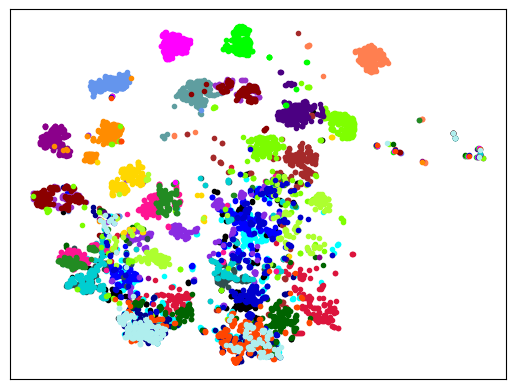

In [50]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
css4 = list(mcolors.CSS4_COLORS.keys())
#我选择了一些较清楚的颜色，更多的类时也能画清晰
color_ind = [2,7,9,10,11,13,14,16,17,19,20,21,25,28,30,31,32,37,38,40,47,51,
         55,60,65,82,85,88,106,110,115,118,120,125,131,135,139,142,146,147]
css4 = [css4[v] for v in color_ind]
label_ids = [4, 7, 8]
for lbi in range(30):
    temp = outs_2d[labels==lbi]
    plt.plot(temp[:,0],temp[:,1],'.',color=css4[lbi])
# plt.title('feats dimensionality reduction visualization by tSNE,test data')
plt.xticks([])
plt.yticks([])
plt.savefig("feats.pdf")  # Save the figure as grid_show.png
plt.show()


In [ ]:
# x_min, x_max = X_tsne.min(0), X_tsne.max(0)
# X_norm = (X_tsne - x_min) / (x_max - x_min)  # 归一化

In [11]:
labels

[0, 1, 2, 3, 4, 5]

## Att

In [13]:
cache = get_local.cache
print(list(cache.keys()))
attention_maps = cache['MultiHeadAttention.forward']
print(len(attention_maps))
attention_maps[0][0].shape

8


(8, 750, 750)

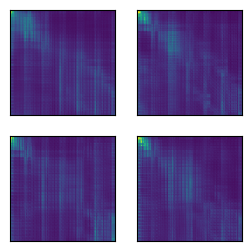

In [95]:
visualize_multi_samples(attention_maps[-1][::2][:4], cols=2,
                        row_scale=1.5, col_scale=1.5,
                        vmin=0.0, vmax=0.01)

## Param. and Flops

In [5]:
# from visualizer import get_local
# get_local.activate()

import math
import sys
import os
from functools import partial

import yaml
import torch
import torch.nn as nn
from tqdm import tqdm
from torch.utils.data import DataLoader
from torch.optim.lr_scheduler import MultiStepLR
import torch.distributed as dist
import torch.multiprocessing as mp
from torch.utils.data.distributed import DistributedSampler
from torch.nn.parallel import DistributedDataParallel as DDP
from torch.distributed import init_process_group, destroy_process_group
import wandb

import utils
from datasets import datasets
from models import models
from torchinfo import summary

In [3]:
config = 'configs/ntu60_xsub/linear_probe.yaml'
with open(config, 'r') as f:
    config = yaml.load(f, Loader=yaml.FullLoader)
    print('config loaded.')
model = models.make(config['model']).cuda()

config loaded.


In [7]:
summary(model, ((1, 1, 2, 90, 25, 3)))

Layer (type:depth-idx)                             Output Shape              Param #
SkTForClassification                               [1, 60]                   --
├─SkTWithDecoder: 1-1                              --                        2,517,248
│    └─JointEmbedding: 2-1                         [2, 750, 256]             14,080
│    │    └─Sequential: 3-1                        [2, 256, 30, 25]          (2,560)
│    └─TransformerEncoder: 2-2                     [2, 750, 256]             --
│    │    └─ModuleList: 3-2                        --                        (6,322,176)
│    └─LayerNorm: 2-3                              [2, 750, 256]             (512)
├─ClassificationHeadLight: 1-2                     [1, 60]                   --
│    └─Rearrange: 2-4                              [1, 2, 750, 256]          --
│    └─Reduce: 2-5                                 [1, 256]                  --
│    └─BatchNorm1d: 2-6                            [1, 256]                  --
│    └─